# MSM Olfactory Low-SWaP-C

**Markov-Switching and Stationarity Modeling for Resource-Constrained Machine Olfaction**: an explanatory walkthrough

This notebook explains the analysis step by step. All computation lives in the `msm_olfactory` package
(`src/`), and the complete run is `python scripts/run_analysis.py`.

**Proof-of-concept question.** Can Markov-switching and stationarity-derived features preserve comparable
classification performance while substantially reducing computational burden, making machine-olfaction approaches
more viable under SWaP-C constraints?

Gas chromatography-mass spectrometry (GC-MS) of urine produces a *total ion chromatogram* (TIC): total ion
intensity over retention time. Rotteveel et al. (2025) classified prostate cancer (PCa) from TICs with an
image-based CNN. This feasibility study represents each TIC by its **dynamics** instead: hidden regimes from a
**Markov switching model (MSM)**, and **rolling ADF/KPSS stationarity tests**. It then asks whether a much smaller
classifier on that compact representation stays in a comparable performance range to the CNN. The aim is
performance retention at lower computational cost, not superiority. This is a proof of concept, not a diagnostic
system.

**Data and privacy.** No source data is stored in this notebook or repository. The single-chromatogram walkthrough (sections 2-4) uses a SYNTHETIC illustrative example; only aggregate results of the real analysis are shown.

**Data.** This uses the public Kaggle dataset `adanrott/prostate-cancer-gc-ms-data`, which is not included in the
repository (see `data/README.md`). If it is not present locally, the notebook falls back to clearly labelled
**SYNTHETIC** demo data, which only shows the mechanics.

Read `docs/methodology.md` for the full method and its limitations before interpreting any number below. `docs/code_architecture.md` maps each step to its module.

In [1]:
%matplotlib inline
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import Image, display

from msm_olfactory import (
    Settings,
    build_tic_image,
    build_tic_table,
    compute_stationarity_features,
    fit_markov_switching_model,
    log_zscore_transform,
    rolling_stationarity_tests,
)
from msm_olfactory import visualization as viz
from msm_olfactory.config import OUTPUT_DIR, REAL_DATA_DIR
from msm_olfactory.data import get_sample_labels
from msm_olfactory.synthetic import ILLUSTRATIVE_LABEL, make_illustrative_tic, make_synthetic_dataset

warnings.filterwarnings("ignore")  # statsmodels convergence/interpolation warnings, as in the source notebook
settings = Settings()

USE_REAL_DATA = (REAL_DATA_DIR / "Samples Demographics.csv").is_file()
if USE_REAL_DATA:
    data_root, results_root = REAL_DATA_DIR, OUTPUT_DIR
    print("Using the real Rotteveel et al. (2025) dataset from", REAL_DATA_DIR.relative_to(REAL_DATA_DIR.parents[2]))
else:
    results_root = OUTPUT_DIR / "synthetic_demo"
    data_root = make_synthetic_dataset(results_root / "synthetic_data")
    print("*** Real data not found: using SYNTHETIC demo data. Numbers below are meaningless. ***")

Using the real Rotteveel et al. (2025) dataset from data\raw\rotteveel_data


## 1. Load the TICs and join the clinical metadata

Each `tic_back.csv` holds retention time and intensity. Clinical labels are joined on the sample ID taken from the
`.D` folder name, using an **exact match, as in the original notebook**. On the public dataset only Boston and Duke
IDs match exactly, so **65 of 267** TICs receive a label (see `data/README.md` for the ID formats).

In [2]:
tic = build_tic_table(data_root)
labelled = get_sample_labels(tic).dropna(subset=["cancer_binary"])
print(
    f"TIC files: {tic['sample_id'].nunique()}   rows: {len(tic):,}   "
    f"rows without metadata: {tic['cancer_status'].isna().sum():,}"
)
print(f"Labelled samples: {len(labelled)}")
pd.crosstab(labelled["hospital"], labelled["cancer_binary"].astype(int).map({0: "Non-Cancer", 1: "Cancer"}))

TIC files: 267   rows: 1,958,444   rows without metadata: 1,481,669
Labelled samples: 65


cancer_binary,Cancer,Non-Cancer
hospital,,
Boston,19,19
Duke,19,8


## 2. A Markov switching model for one chromatogram

> **Synthetic illustrative example.** Sections 2-4 explain the method on a randomly generated chromatogram (`make_illustrative_tic`), so no source sample is shown. It is not data, and its numbers are not results. Section 5 reports the real analysis.

The TIC is transformed with $y_t = \text{zscore}(\log(1 + \max(x_t, 0)))$ and modelled as

$$y_t = \mu_{S_t} + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2), \qquad
P(S_t = i \mid S_{t-1} = j) = p_{ij},$$

with $K = 3$ hidden regimes, regime-specific means, one shared variance (`switching_variance=False`) and a
time-invariant transition matrix. Fitting uses statsmodels `MarkovRegression` (EM, 20 random start searches). The
regimes are read from the **smoothed** probabilities $P(S_t = i \mid y_{1:T})$.

Synthetic illustrative example: 3000 points, k = 3, log-likelihood -1644.1, AIC 3308.1, BIC 3368.2
Regime occupancy: {0: '11.4%', 1: '26.4%', 2: '62.3%'}

Transition matrix, P[i, j] = P(S_t = i | S_(t-1) = j)  (columns sum to 1):
      from 0  from 1  from 2
to 0  0.9689  0.0133  0.0000
to 1  0.0311  0.9672  0.0078
to 2  0.0000  0.0195  0.9922


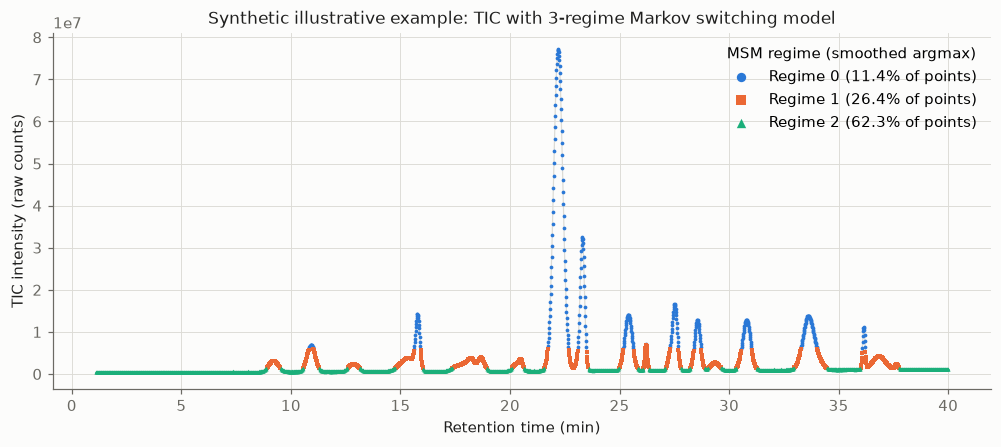

In [3]:
# SYNTHETIC illustrative chromatogram (not source data, not a result)
SAMPLE_LABEL = ILLUSTRATIVE_LABEL
time, intensity = make_illustrative_tic()
fit = fit_markov_switching_model(SAMPLE_LABEL, intensity, settings, seed=settings.base_seed)
print(
    f"{SAMPLE_LABEL}: {fit.n_points} points, k = {fit.k_used}, log-likelihood {fit.llf:.1f}, AIC {fit.aic:.1f}, BIC {fit.bic:.1f}"
)
print("Regime occupancy:", {r: f"{100 * np.mean(fit.regimes == r):.1f}%" for r in range(fit.k_used)})
print("\nTransition matrix, P[i, j] = P(S_t = i | S_(t-1) = j)  (columns sum to 1):")
transition = pd.DataFrame(
    fit.transition, index=[f"to {i}" for i in range(fit.k_used)], columns=[f"from {j}" for j in range(fit.k_used)]
)
print(transition.round(4))
viz.plot_msm_regimes(time, intensity, fit.regimes, fit.k_used, SAMPLE_LABEL)

Regimes differ only in their mean, so the MSM splits the chromatogram into intensity levels: baseline,
intermediate, and peak-dominated points. **Regime numbers are arbitrary for each fit** (label switching). "Regime 0" in
one sample is not the same physical state as "regime 0" in another, which limits how the per-sample regime features
can be compared (see the methodology document).

## 3. Rolling stationarity tests

ADF and KPSS are run on 200-point windows every 20 points of the transformed series. The two tests have opposite
null hypotheses:

* **ADF:** H0 is a unit root. A low p-value means the window is stationary.
* **KPSS:** H0 is stationarity. A low p-value means the window is non-stationary.

statsmodels clips KPSS p-values to the interval [0.01, 0.10].

n_station_windows            141
frac_adf_p_lt_0_05        0.1348
frac_adf_p_lt_0_01        0.0993
frac_kpss_p_lt_0_05        0.695
frac_kpss_p_lt_0_01          0.0
frac_both_p_lt_0_05       0.0851
frac_adf_high_kpss_low    0.6099
mean_adf_p                0.3669
median_adf_p              0.3521
mean_kpss_p               0.0367
median_kpss_p             0.0102


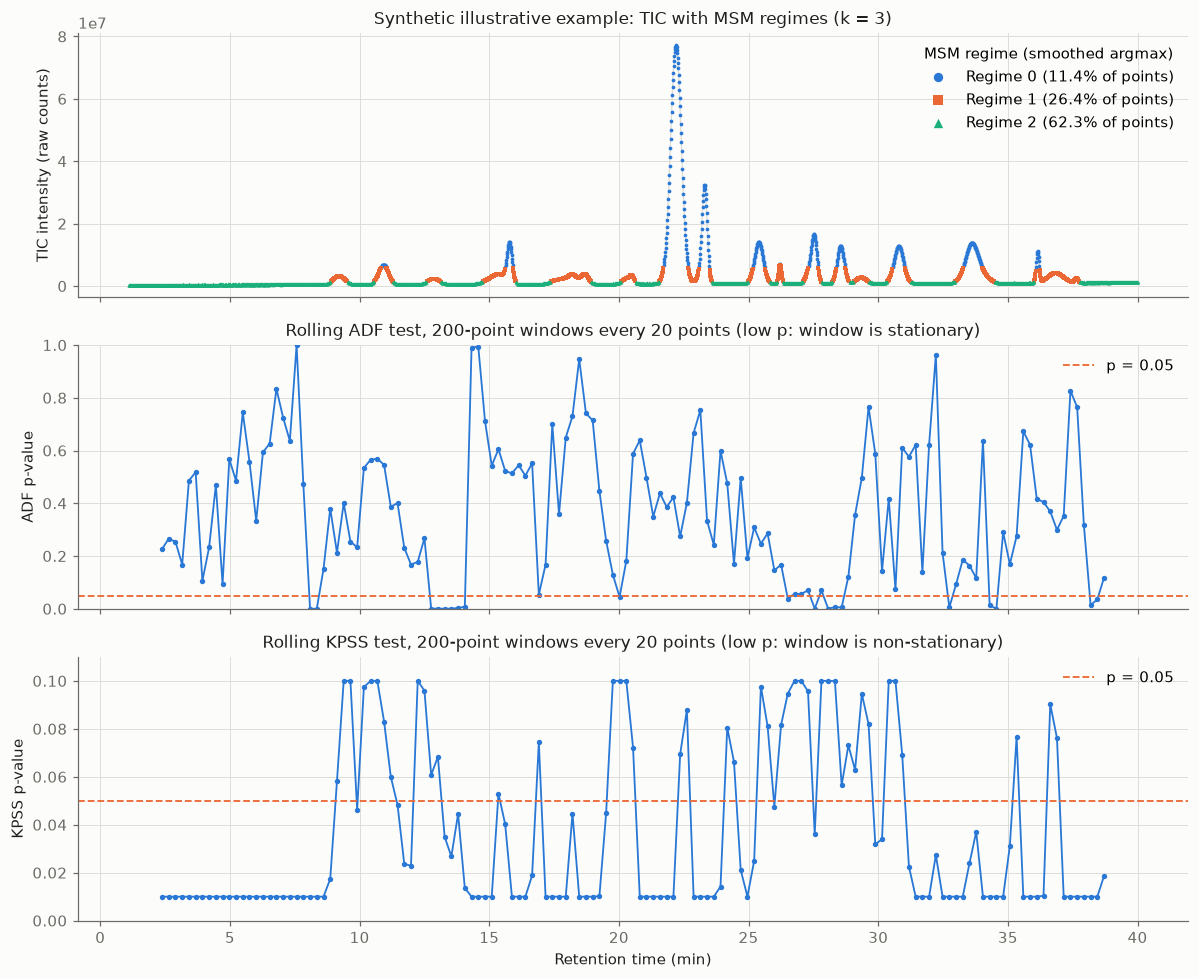

In [4]:
rolling = rolling_stationarity_tests(
    log_zscore_transform(intensity), time, settings.station_window, settings.station_step
)
stationarity_features = compute_stationarity_features(SAMPLE_LABEL, rolling["adf_p"], rolling["kpss_p"])
print(pd.Series(stationarity_features).drop("sample_id").round(4).to_string())
viz.plot_msm_stationarity_panel(
    time,
    intensity,
    fit.regimes,
    fit.k_used,
    rolling["times"],
    rolling["adf_p"],
    rolling["kpss_p"],
    SAMPLE_LABEL,
    settings.station_window,
    settings.station_step,
)

## 4. The 4 x 256 "TIC image"

Intensity, MSM regime, $1 - p_{ADF}$ and $1 - p_{KPSS}$ are resampled onto 256 time bins. Each row is scaled to
[0, 1] between its own 1st and 99th percentiles, and the image is stored as 8-bit grayscale. Rows 2-4 are MSM and
stationarity channels, so the CNN trained on these images is **not** an intensity-only model.

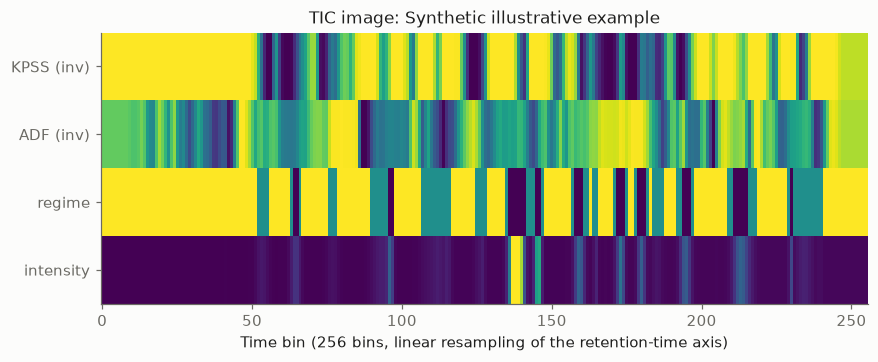

In [5]:
image, _ = build_tic_image(
    time,
    intensity,
    fit.regimes,
    fit.k_used,
    rolling["times"],
    rolling["adf_p"],
    rolling["kpss_p"],
    settings.image_width,
)
viz.plot_tic_image(image, SAMPLE_LABEL)

## 5. Results of the full pipeline

The steps below fit all 267 TICs and train the models. That takes several minutes, so they run in
`scripts/run_analysis.py` and this notebook reads its saved outputs. The run includes:

* per-sample features
* logistic regression and random forest baselines
* PCA and ComBat harmonization by hospital
* the TIC-image CNN, the MSM-feature MLP and the gated multi-modal ResNet18

Each sample's MSM uses a fixed per-sample seed, so its regimes and numbers can differ slightly from the
single-sample cell above, which used `seed=settings.base_seed`.

In [6]:
summary_path = results_root / "results" / "run_summary.json"
if not summary_path.is_file():
    raise FileNotFoundError(
        f"{summary_path} not found. Run: python scripts/run_analysis.py" + ("" if USE_REAL_DATA else " --synthetic")
    )
run = json.loads(summary_path.read_text())
print("Synthetic data:", run["data_root_is_synthetic"])
print(
    "Model inputs:",
    run["pca"]["n_model_features"],
    "features for",
    run["pca"]["n_labelled_samples"],
    "labelled samples",
)

rows = {
    name: run["tabular_baselines"][key]
    for name, key in [
        ("LogReg, MSM-group features", "logreg_msm_group"),
        ("LogReg, all features", "logreg_all_features"),
        ("Random forest, all features", "random_forest_all_features"),
    ]
}
tabular = pd.DataFrame(rows).T[["accuracy", "f1", "roc_auc", "pr_auc"]].astype(float).round(3)
tabular

Synthetic data: False
Model inputs: 30 features for 65 labelled samples


,accuracy,f1,roc_auc,pr_auc
"LogReg, MSM-group features",0.50,0.545,0.490,0.700
"LogReg, all features",0.35,0.381,0.312,0.590
"Random forest, all features",0.45,0.522,0.271,0.496


In [7]:
if "deep_models" in run:
    dm = run["deep_models"]
    deep = pd.DataFrame(
        {
            "best val F1 (selected on val)": dm["best_val_f1"],
            "best epoch": dm["best_epoch"],
            f"val F1 at epoch {settings.epochs}": dm["final_epoch_val_f1"],
        }
    ).round(3)
    display(deep)
    oh = dm["computational_overhead"]
    print(
        f"Parameters: CNN {oh['cnn_parameters']:,} vs MLP {oh['mlp_parameters']:,}; "
        f"inputs per sample: {oh['cnn_inputs_per_sample']} vs {oh['mlp_inputs_per_sample']}; "
        f"forward pass per batch: {1e3 * oh['cnn_seconds_per_batch']:.2f} ms vs {1e3 * oh['mlp_seconds_per_batch']:.3f} ms"
    )
    print("Note:", oh["note"])

,best val F1 (selected on val),best epoch,val F1 at epoch 20
TIC-image CNN,0.750,1,0.571
MSM-feature MLP,0.538,6,0.480
Multi-modal gated ResNet18,0.750,1,0.583


Parameters: CNN 1,072,066 vs MLP 4,130; inputs per sample: 1024 vs 30; forward pass per batch: 5.00 ms vs 0.126 ms
Note: Forward pass only. Excludes MSM fitting and rolling ADF/KPSS, which the MLP's inputs and the image's rows 1-3 both require.


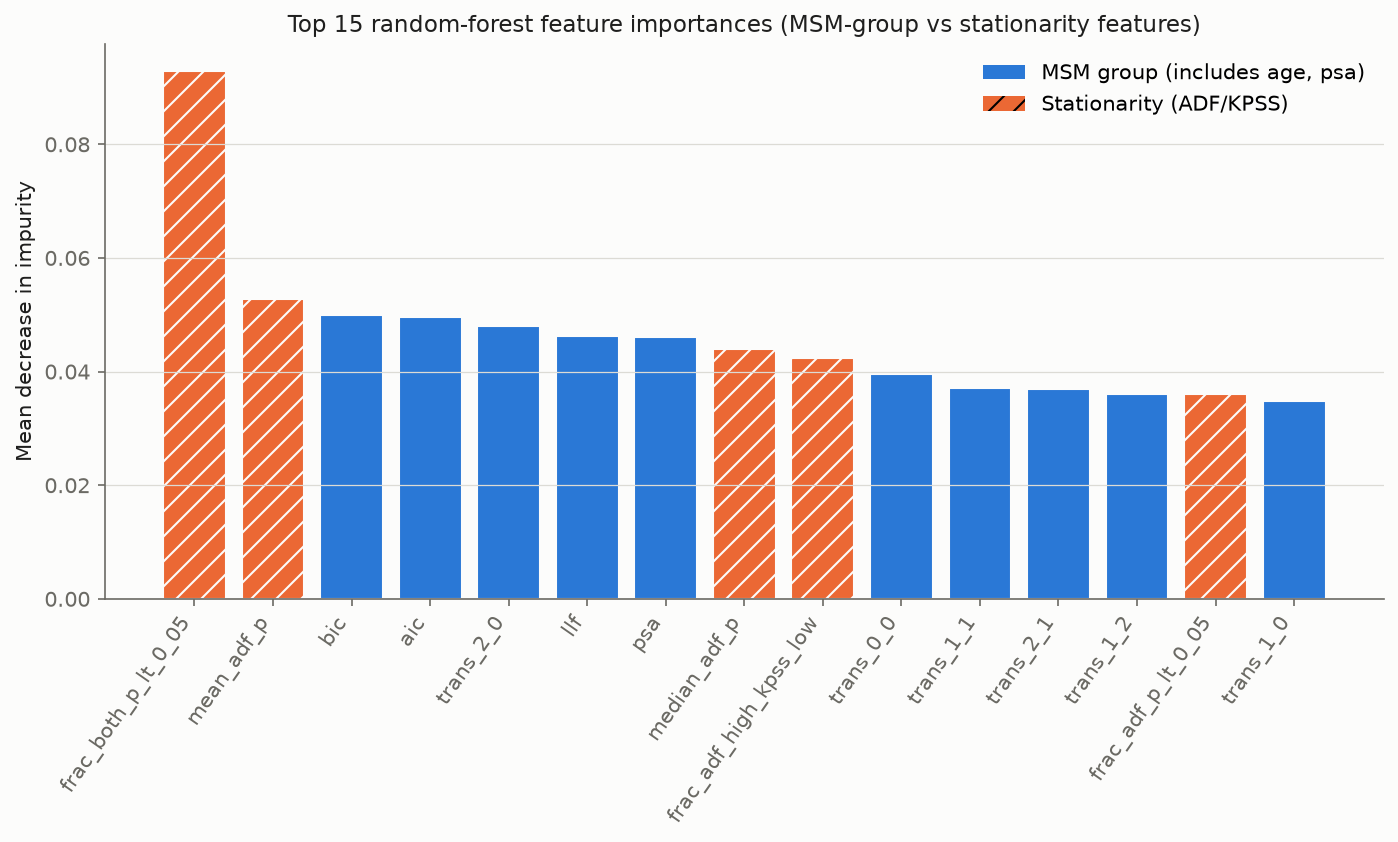

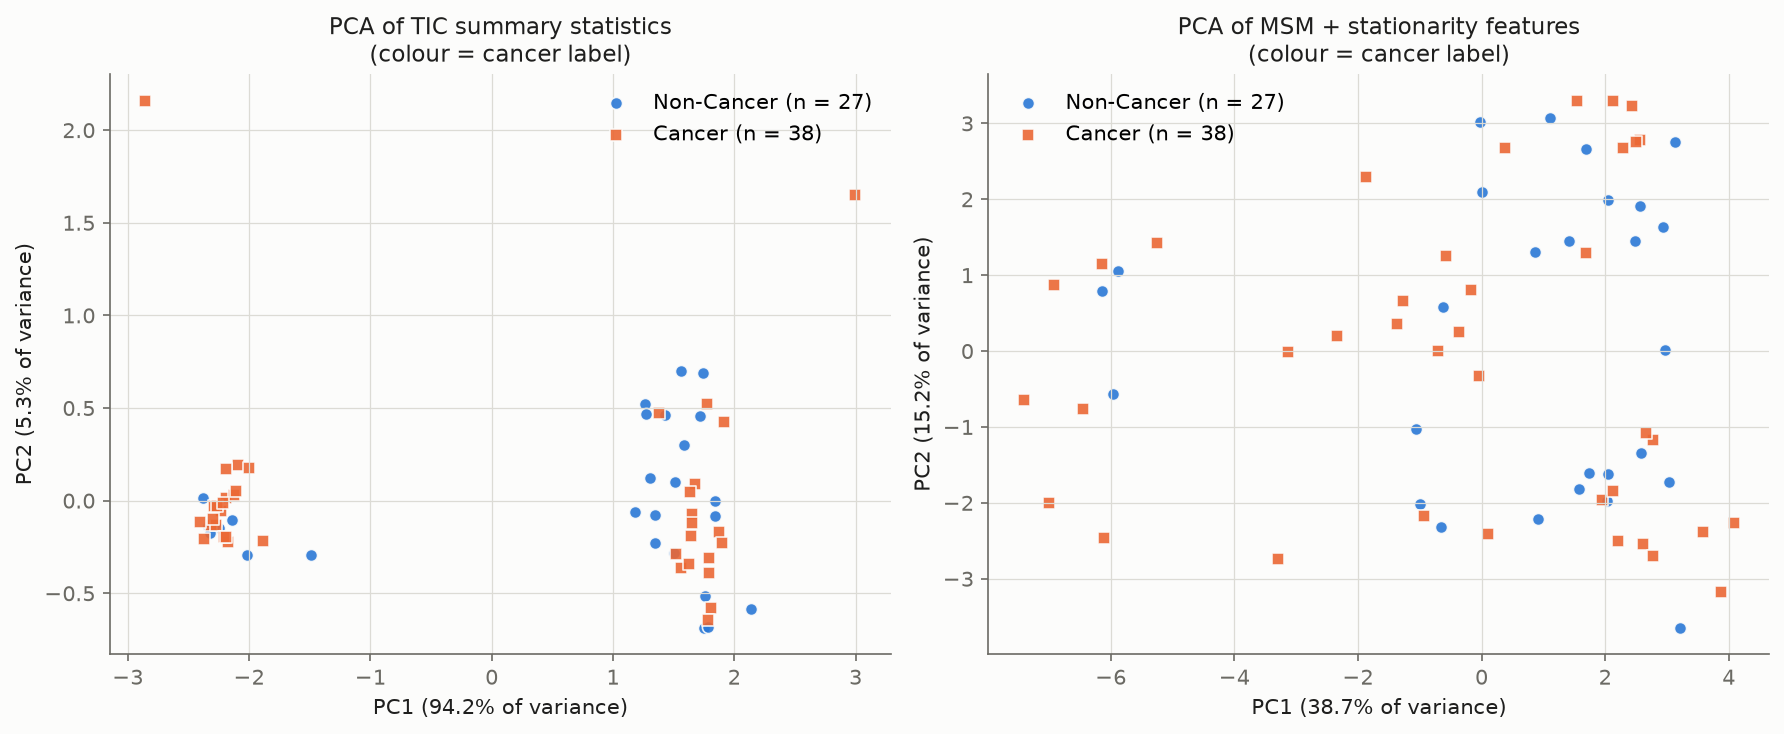

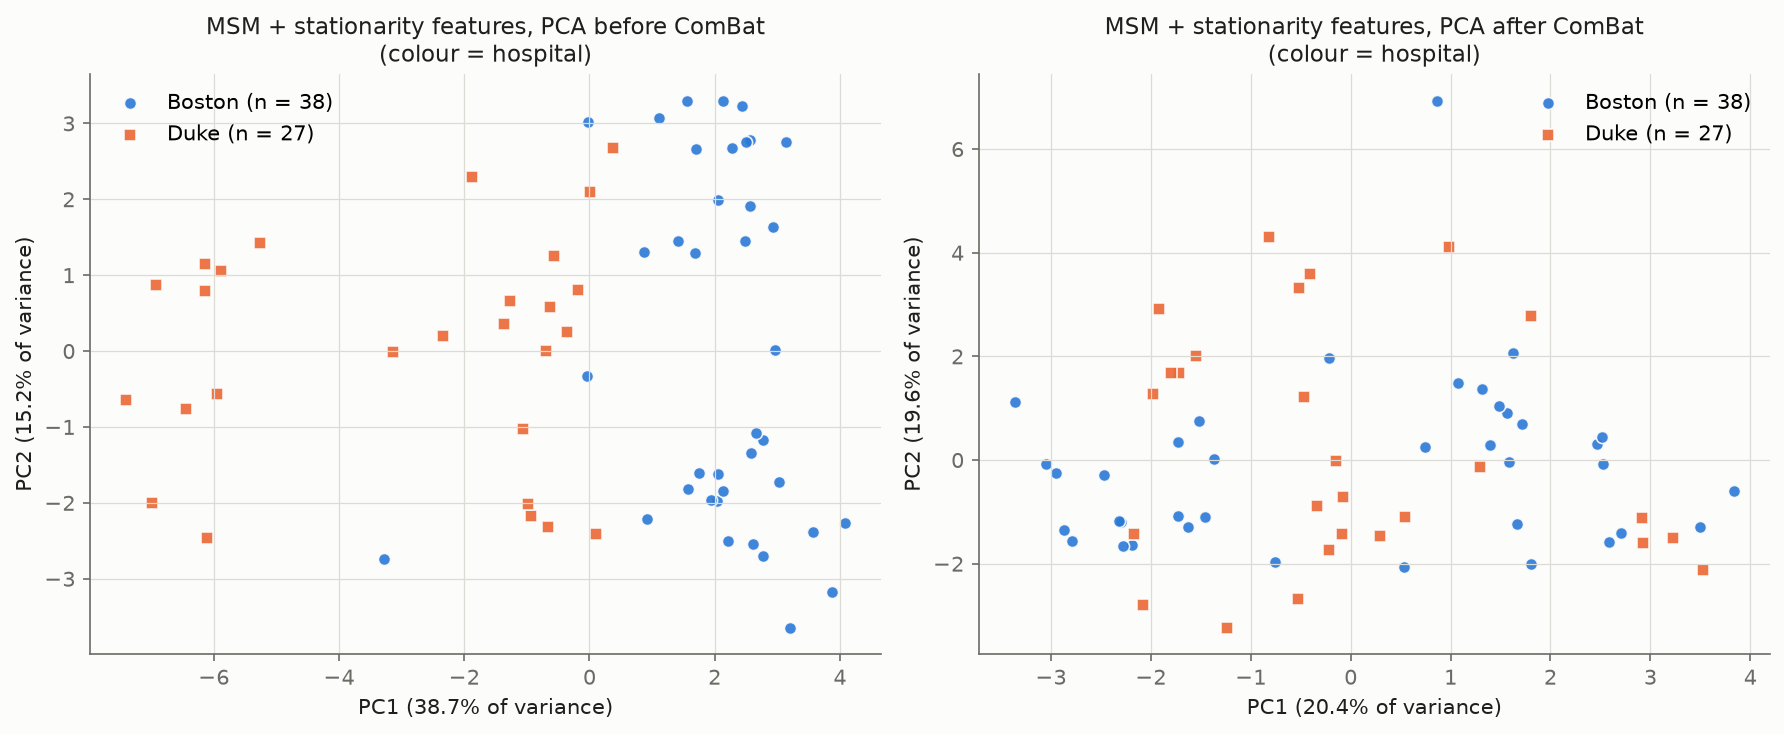

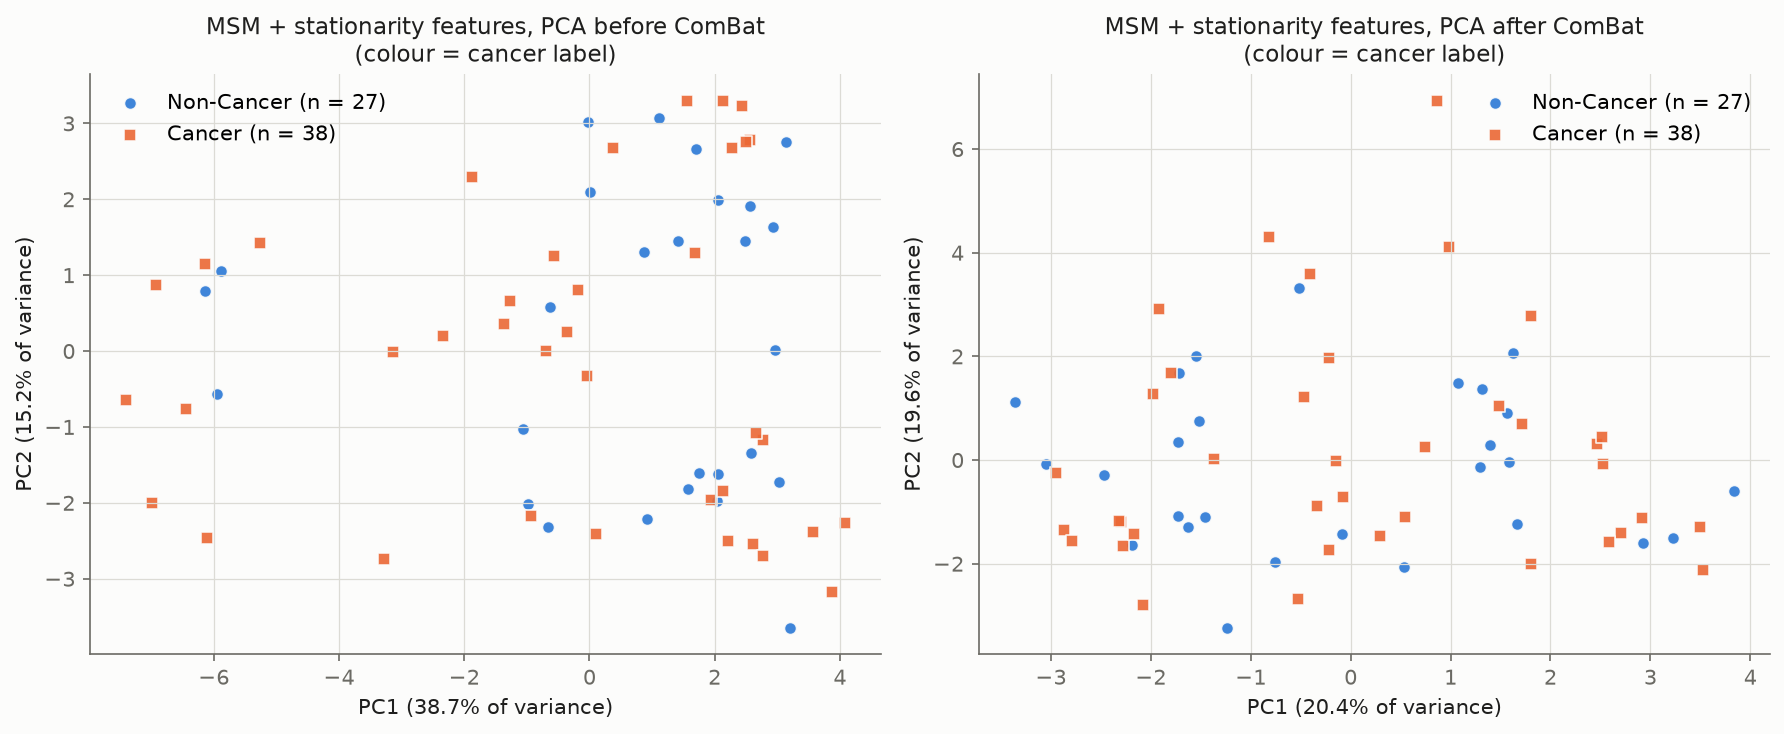

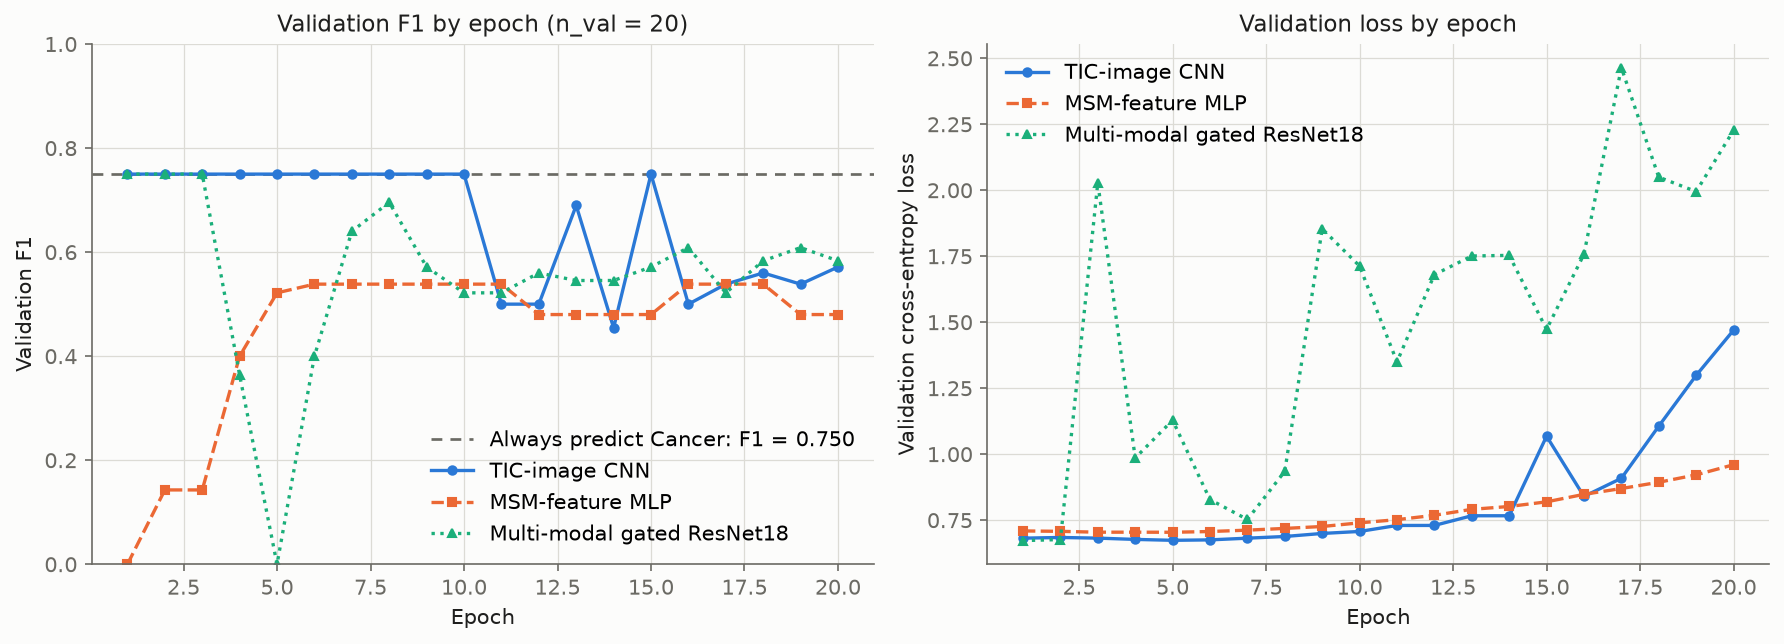

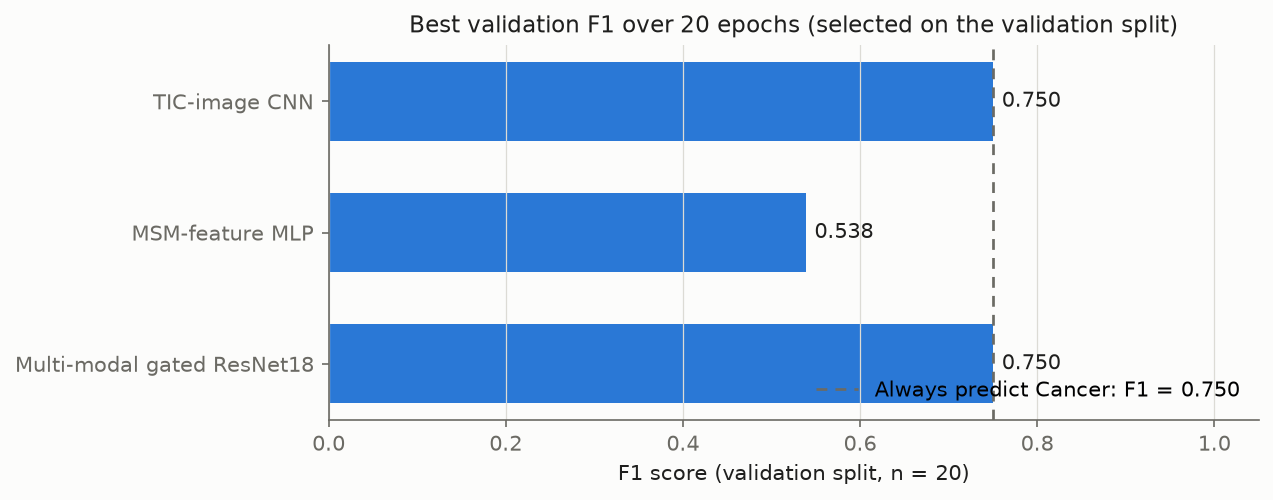

In [8]:
for name in [
    "03_feature_importance_rf",
    "06_pca_tic_vs_msm_features",
    "07_pca_before_after_combat_by_hospital",
    "08_pca_before_after_combat_by_label",
    "09_deep_model_validation_curves",
    "10_deep_model_comparison_f1",
]:
    path = results_root / "figures" / f"{name}.png"
    if path.is_file():
        display(Image(filename=str(path)))

## 6. Robustness across seeds, and the computational trade study

Two analyses were added in this reconstruction. Neither is in the original notebook.

* **Seed study** (`scripts/run_seed_study.py`): the same protocol repeated under 3 MSM seeds x 5 PyTorch seeds. It is
  compared with the six runs quoted in the original technical report (hollow diamonds), which are **reported values,
  not reproduced ones**.
* **SWaP-C trade study** (`scripts/run_swap_analysis.py`): classifier latency, model size and input size, **plus**
  the per-sample cost of computing the MSM and stationarity inputs that both implemented models need.

,mean,std,min,max
TIC-image CNN | best_val_f1,0.758,0.012,0.750,0.786
TIC-image CNN | final_val_f1,0.653,0.068,0.538,0.769
MSM-feature MLP | best_val_f1,0.708,0.062,0.538,0.774
MSM-feature MLP | final_val_f1,0.623,0.072,0.480,0.759
Multi-modal gated ResNet18 | best_val_f1,0.761,0.017,0.733,0.800
Multi-modal gated ResNet18 | final_val_f1,0.569,0.088,0.364,0.720


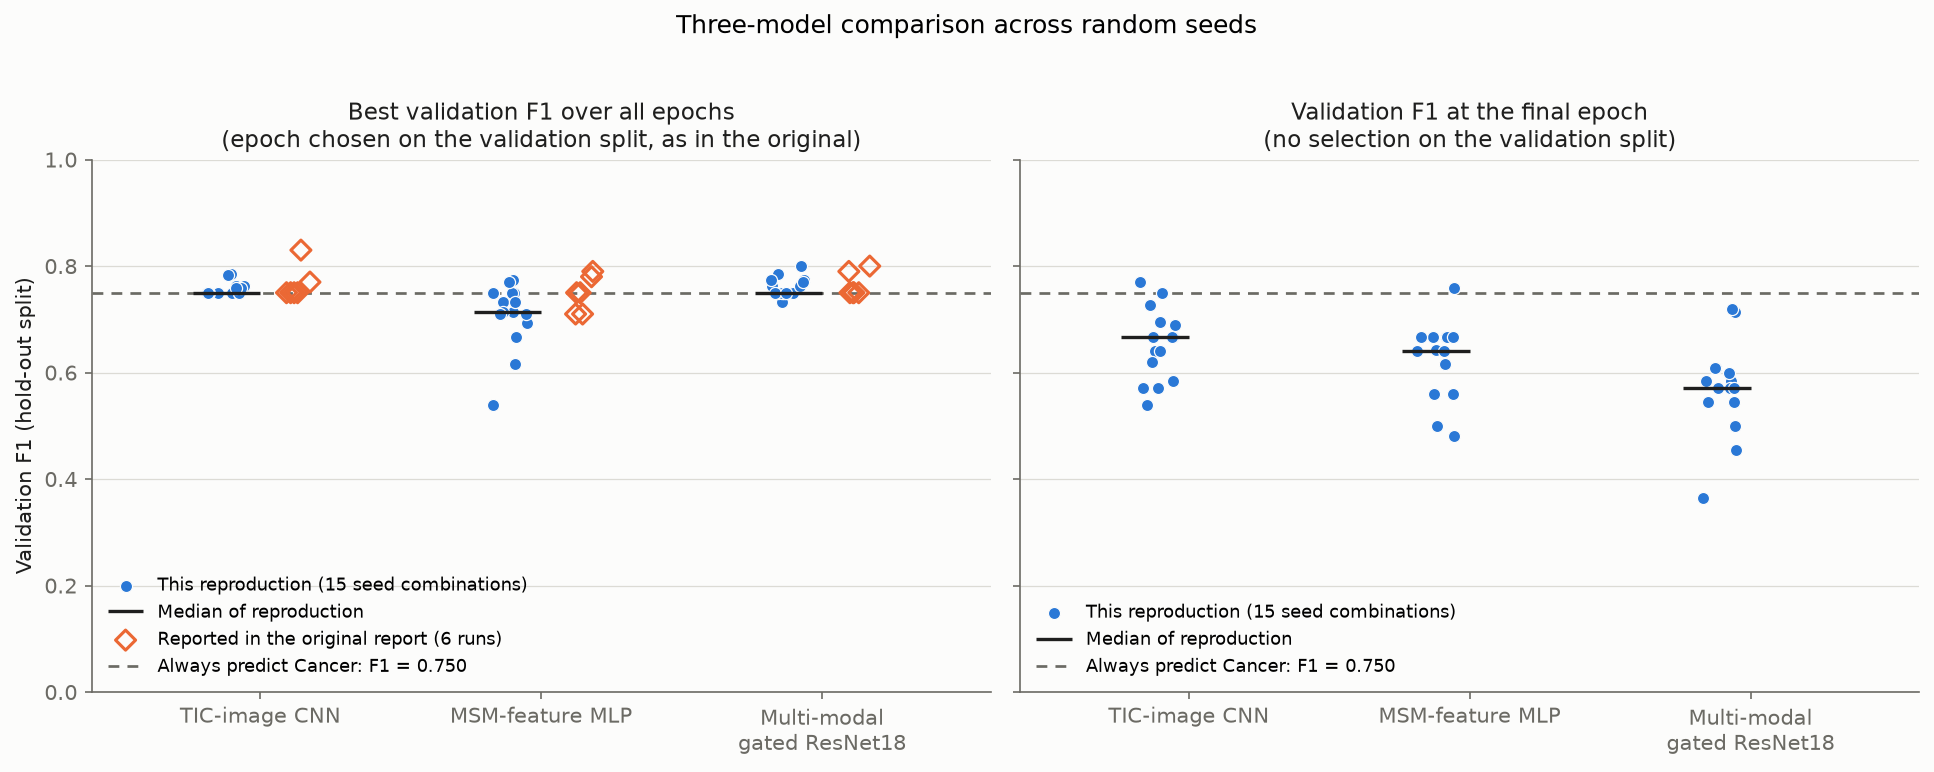

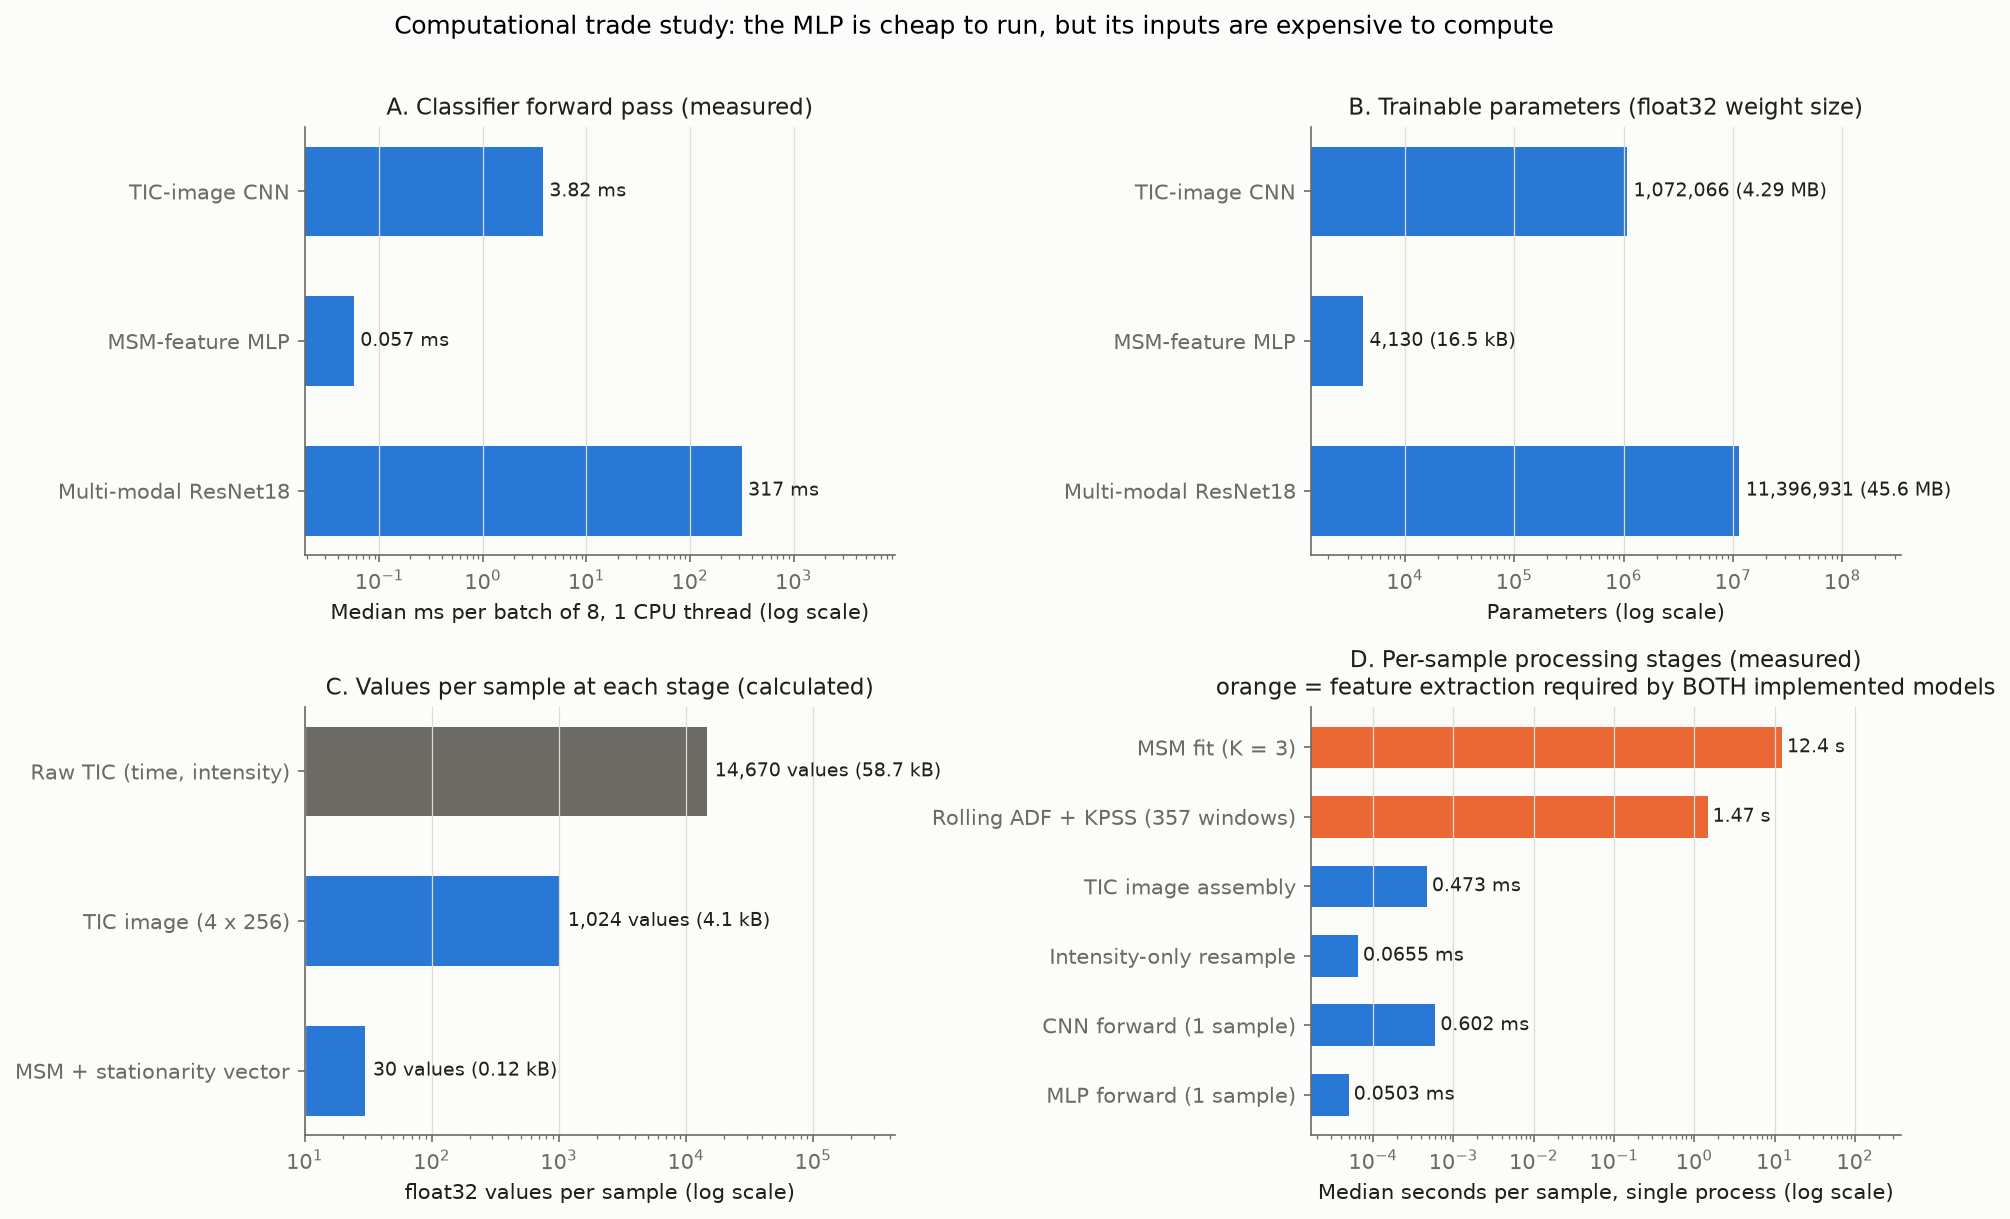

In [9]:
seed_csv = results_root / "results" / "seed_study.csv"
if seed_csv.is_file():
    seeds = pd.read_csv(seed_csv)
    cols = [c for c in seeds.columns if c.endswith("best_val_f1") or c.endswith("final_val_f1")]
    display(seeds[cols].describe().loc[["mean", "std", "min", "max"]].round(3).T)
for name in ["11_three_model_f1_seed_study", "12_swap_c_trade_study"]:
    path = results_root / "figures" / f"{name}.png"
    if path.is_file():
        display(Image(filename=str(path)))

## 7. How to read these results

* The validation split has **20 samples** (one split, `random_state=42`). One misclassified sample moves F1 by
  several points, so differences between models of this size are within noise.
* The deep-model score is the **best validation F1 over 20 epochs**, so the validation set chose the epoch. It is an
  optimistic estimate, and no independent test set exists.
* ComBat and the scaler are fitted on all 65 labelled samples **with the label as a protected covariate**, before
  the split. That leaks label information into the validation features.
* The 30 model inputs include the clinical covariates **age and PSA**, so the "MSM" models are not dynamics-only.
* Only two hospitals (Boston, Duke) contribute labelled samples.

These are the original notebook's choices, reproduced deliberately. `docs/methodology.md` explains each one and
suggests corrections.